# Crop disease detection - YOLOv8 training
Dataset: Roboflow *Plants Diseases Detection and Classification* v12 (29 classes). Run cells top to bottom.

In [1]:
from pathlib import Path
import torch, yaml
from ultralytics import YOLO

ROOT = Path.cwd()
DATASET = ROOT / "Plants Diseases Detection and Classification.v12i.yolov8"
print("CUDA:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

CUDA: True NVIDIA GeForce RTX 3050 6GB Laptop GPU


The Roboflow `data.yaml` uses `../train/images` paths, which often fail to resolve. We write a new yaml with absolute paths.

In [2]:
src = yaml.safe_load((DATASET / "data.yaml").read_text())
cfg = {
    "path": str(DATASET),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": src["nc"],
    "names": src["names"],
}
DATA_YAML = ROOT / "data_local.yaml"
DATA_YAML.write_text(yaml.safe_dump(cfg, sort_keys=False))
for s in ("train", "valid", "test"):
    print(s, len(list((DATASET / s / "images").glob("*"))), "images")
print(cfg["nc"], "classes")

train 2017 images
valid 250 images
test 249 images
29 classes


## Train
Starts from pretrained `yolov8s.pt` (transfer learning). Batch 16 at 640px fits a 6 GB GPU; if you get a CUDA out-of-memory error, set `BATCH = 8`. `patience` stops early if validation stops improving.

In [3]:
MODEL = "yolov8s.pt"   # yolov8n.pt = faster/smaller, yolov8m.pt = more accurate (needs more VRAM)
EPOCHS = 40
IMGSZ = 640
BATCH = 16

model = YOLO(MODEL)
results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    device=0,
    patience=0,
    workers=2,          # keep low on Windows to avoid dataloader issues
    project=str(ROOT / "runs"),
    name="crop_disease",
    exist_ok=True,
)

New https://pypi.org/project/ultralytics/8.4.192 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.146  Python-3.10.0 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=G:\crop disease\Yolo\data_local.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixu

## Evaluate on the validation and test splits
Look at mAP50 (higher is better) and per-class results to see which diseases the model confuses.

In [4]:
BEST = ROOT / "runs" / "crop_disease" / "weights" / "best.pt"
model = YOLO(str(BEST))
val = model.val(data=str(DATA_YAML), split="val", device=0)
print("val  mAP50:", round(val.box.map50, 3), " mAP50-95:", round(val.box.map, 3))
test = model.val(data=str(DATA_YAML), split="test", device=0)
print("test mAP50:", round(test.box.map50, 3), " mAP50-95:", round(test.box.map, 3))

Ultralytics 8.4.146  Python-3.10.0 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)
Model summary (fused): 72 layers, 11,136,807 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 900.4361.7 MB/s, size: 85.3 KB)
val: Scanning G:\crop disease\Yolo\Plants Diseases Detection and Classification.v12i.yolov8\valid\labels.cache... 250 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 250/250  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 4.1it/s 3.9s0.2s
                   all        250        884      0.571      0.538      0.574      0.409
       Apple Scab Leaf          6         14       0.46      0.286      0.361      0.242
            Apple leaf          9         23      0.833      0.913       0.93      0.662
       Apple rust leaf         11         39      0.837      0.526      0.593      0.349
      Bell_pepper leaf          3         11      0.542  

In [5]:
# Per-class mAP50, worst first
import pandas as pd
names = model.names
df = pd.DataFrame({"class": [names[i] for i in test.box.ap_class_index], "mAP50": test.box.ap50}).sort_values("mAP50")
df

,class,mAP50
7,Corn Gray leaf spot,0.000000
11,Potato leaf early blight,0.000000
21,Tomato leaf late blight,0.148789
12,Potato leaf late blight,0.180136
23,Tomato leaf yellow virus,0.214049
18,Tomato Early blight leaf,0.338094
25,Tomato mold leaf,0.339602
19,Tomato Septoria leaf spot,0.392758
20,Tomato leaf bacterial spot,0.420771
4,Bell_pepper leaf,0.510553


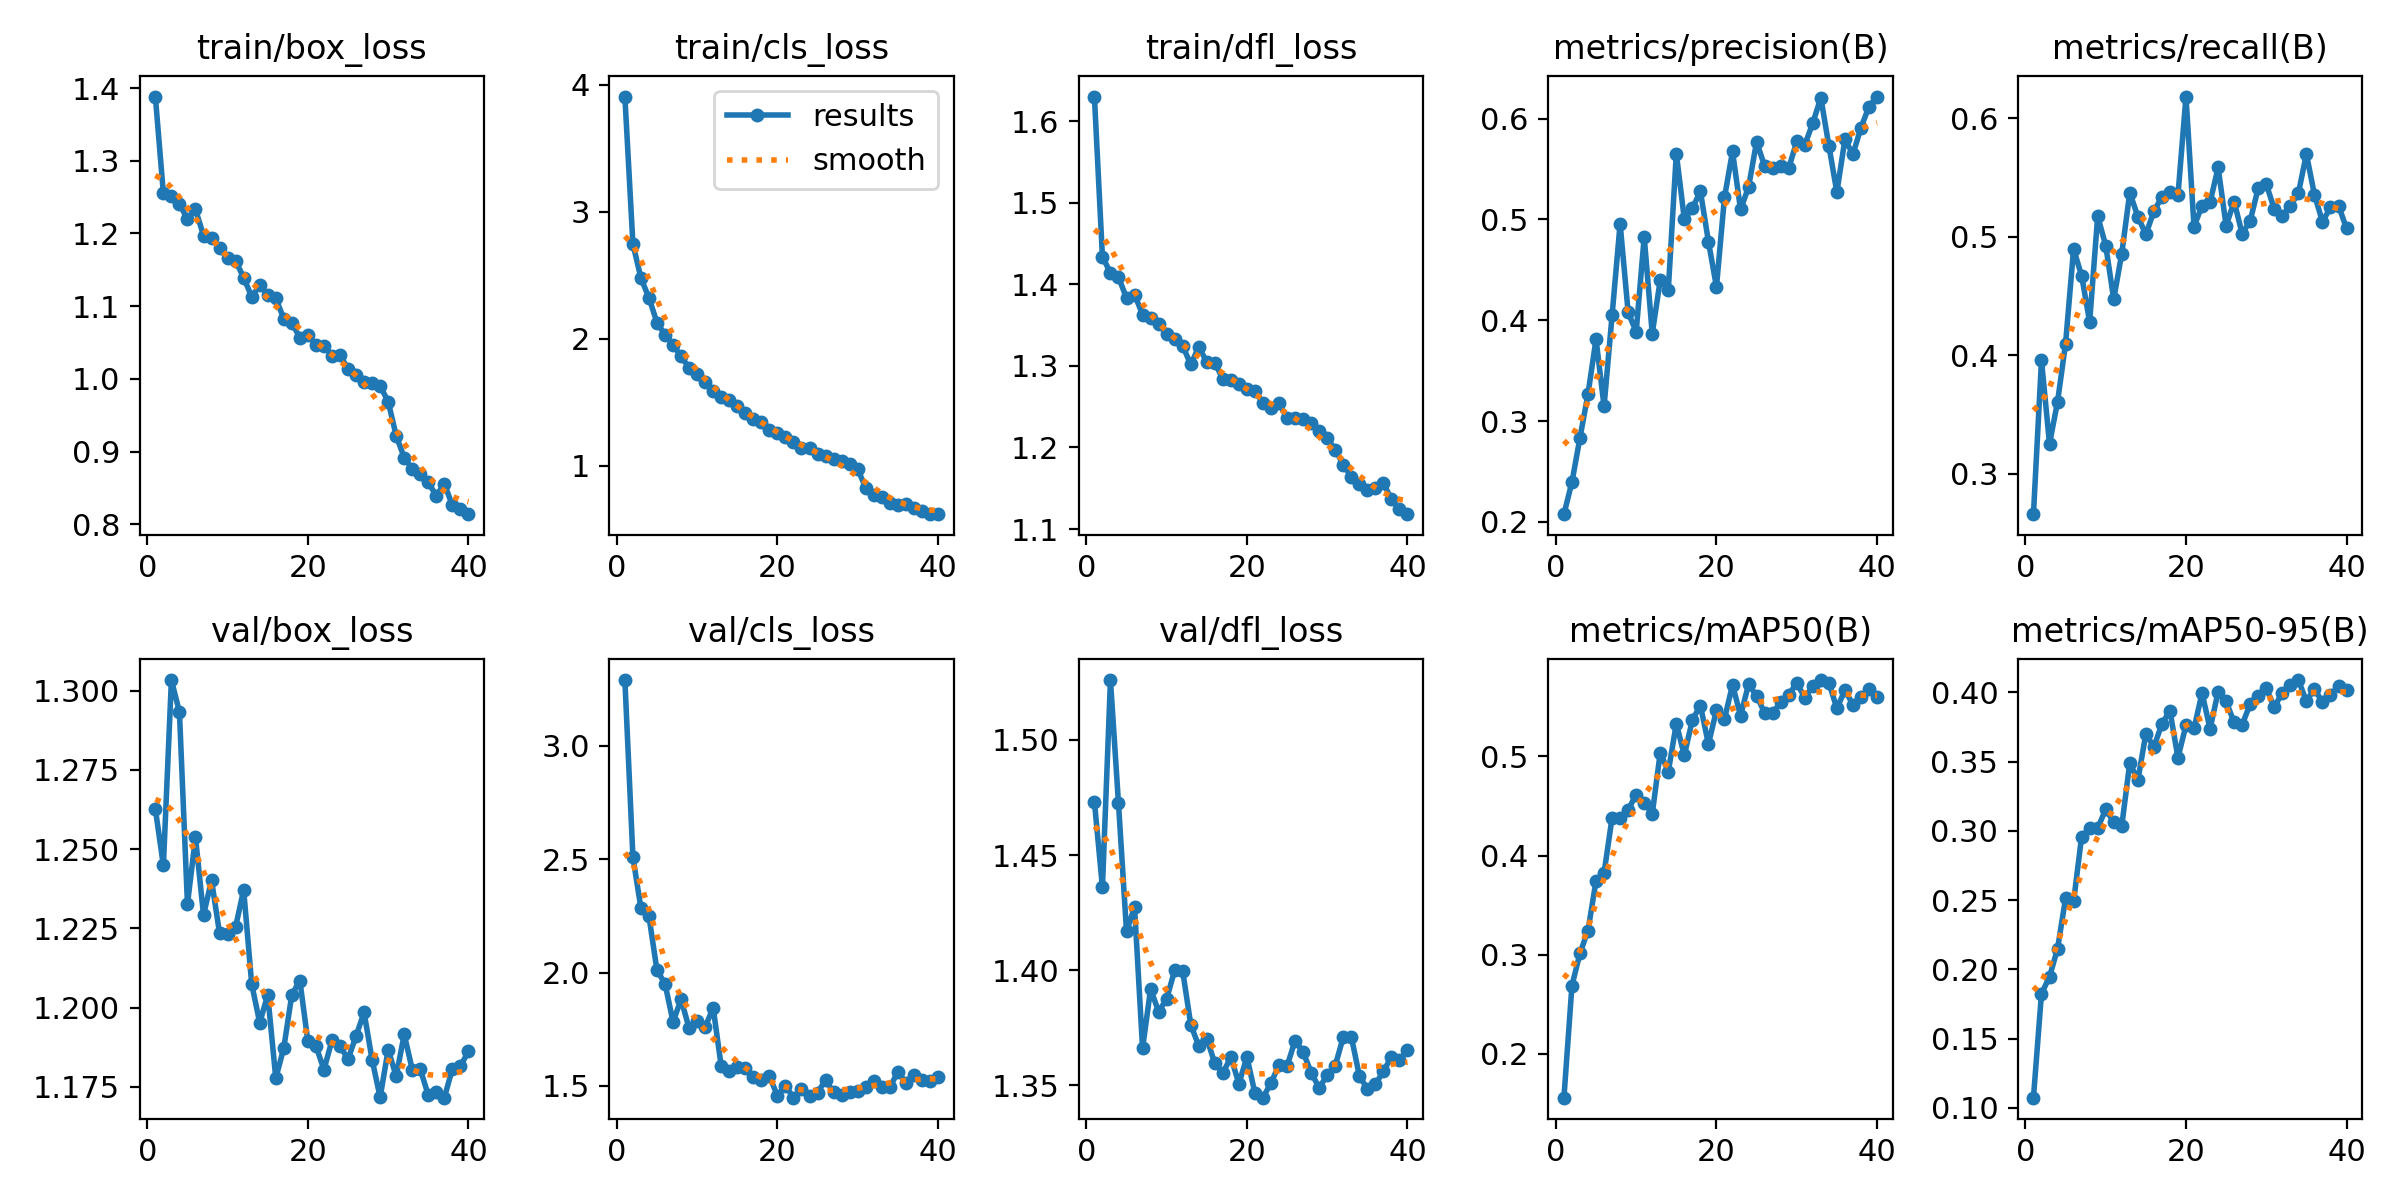

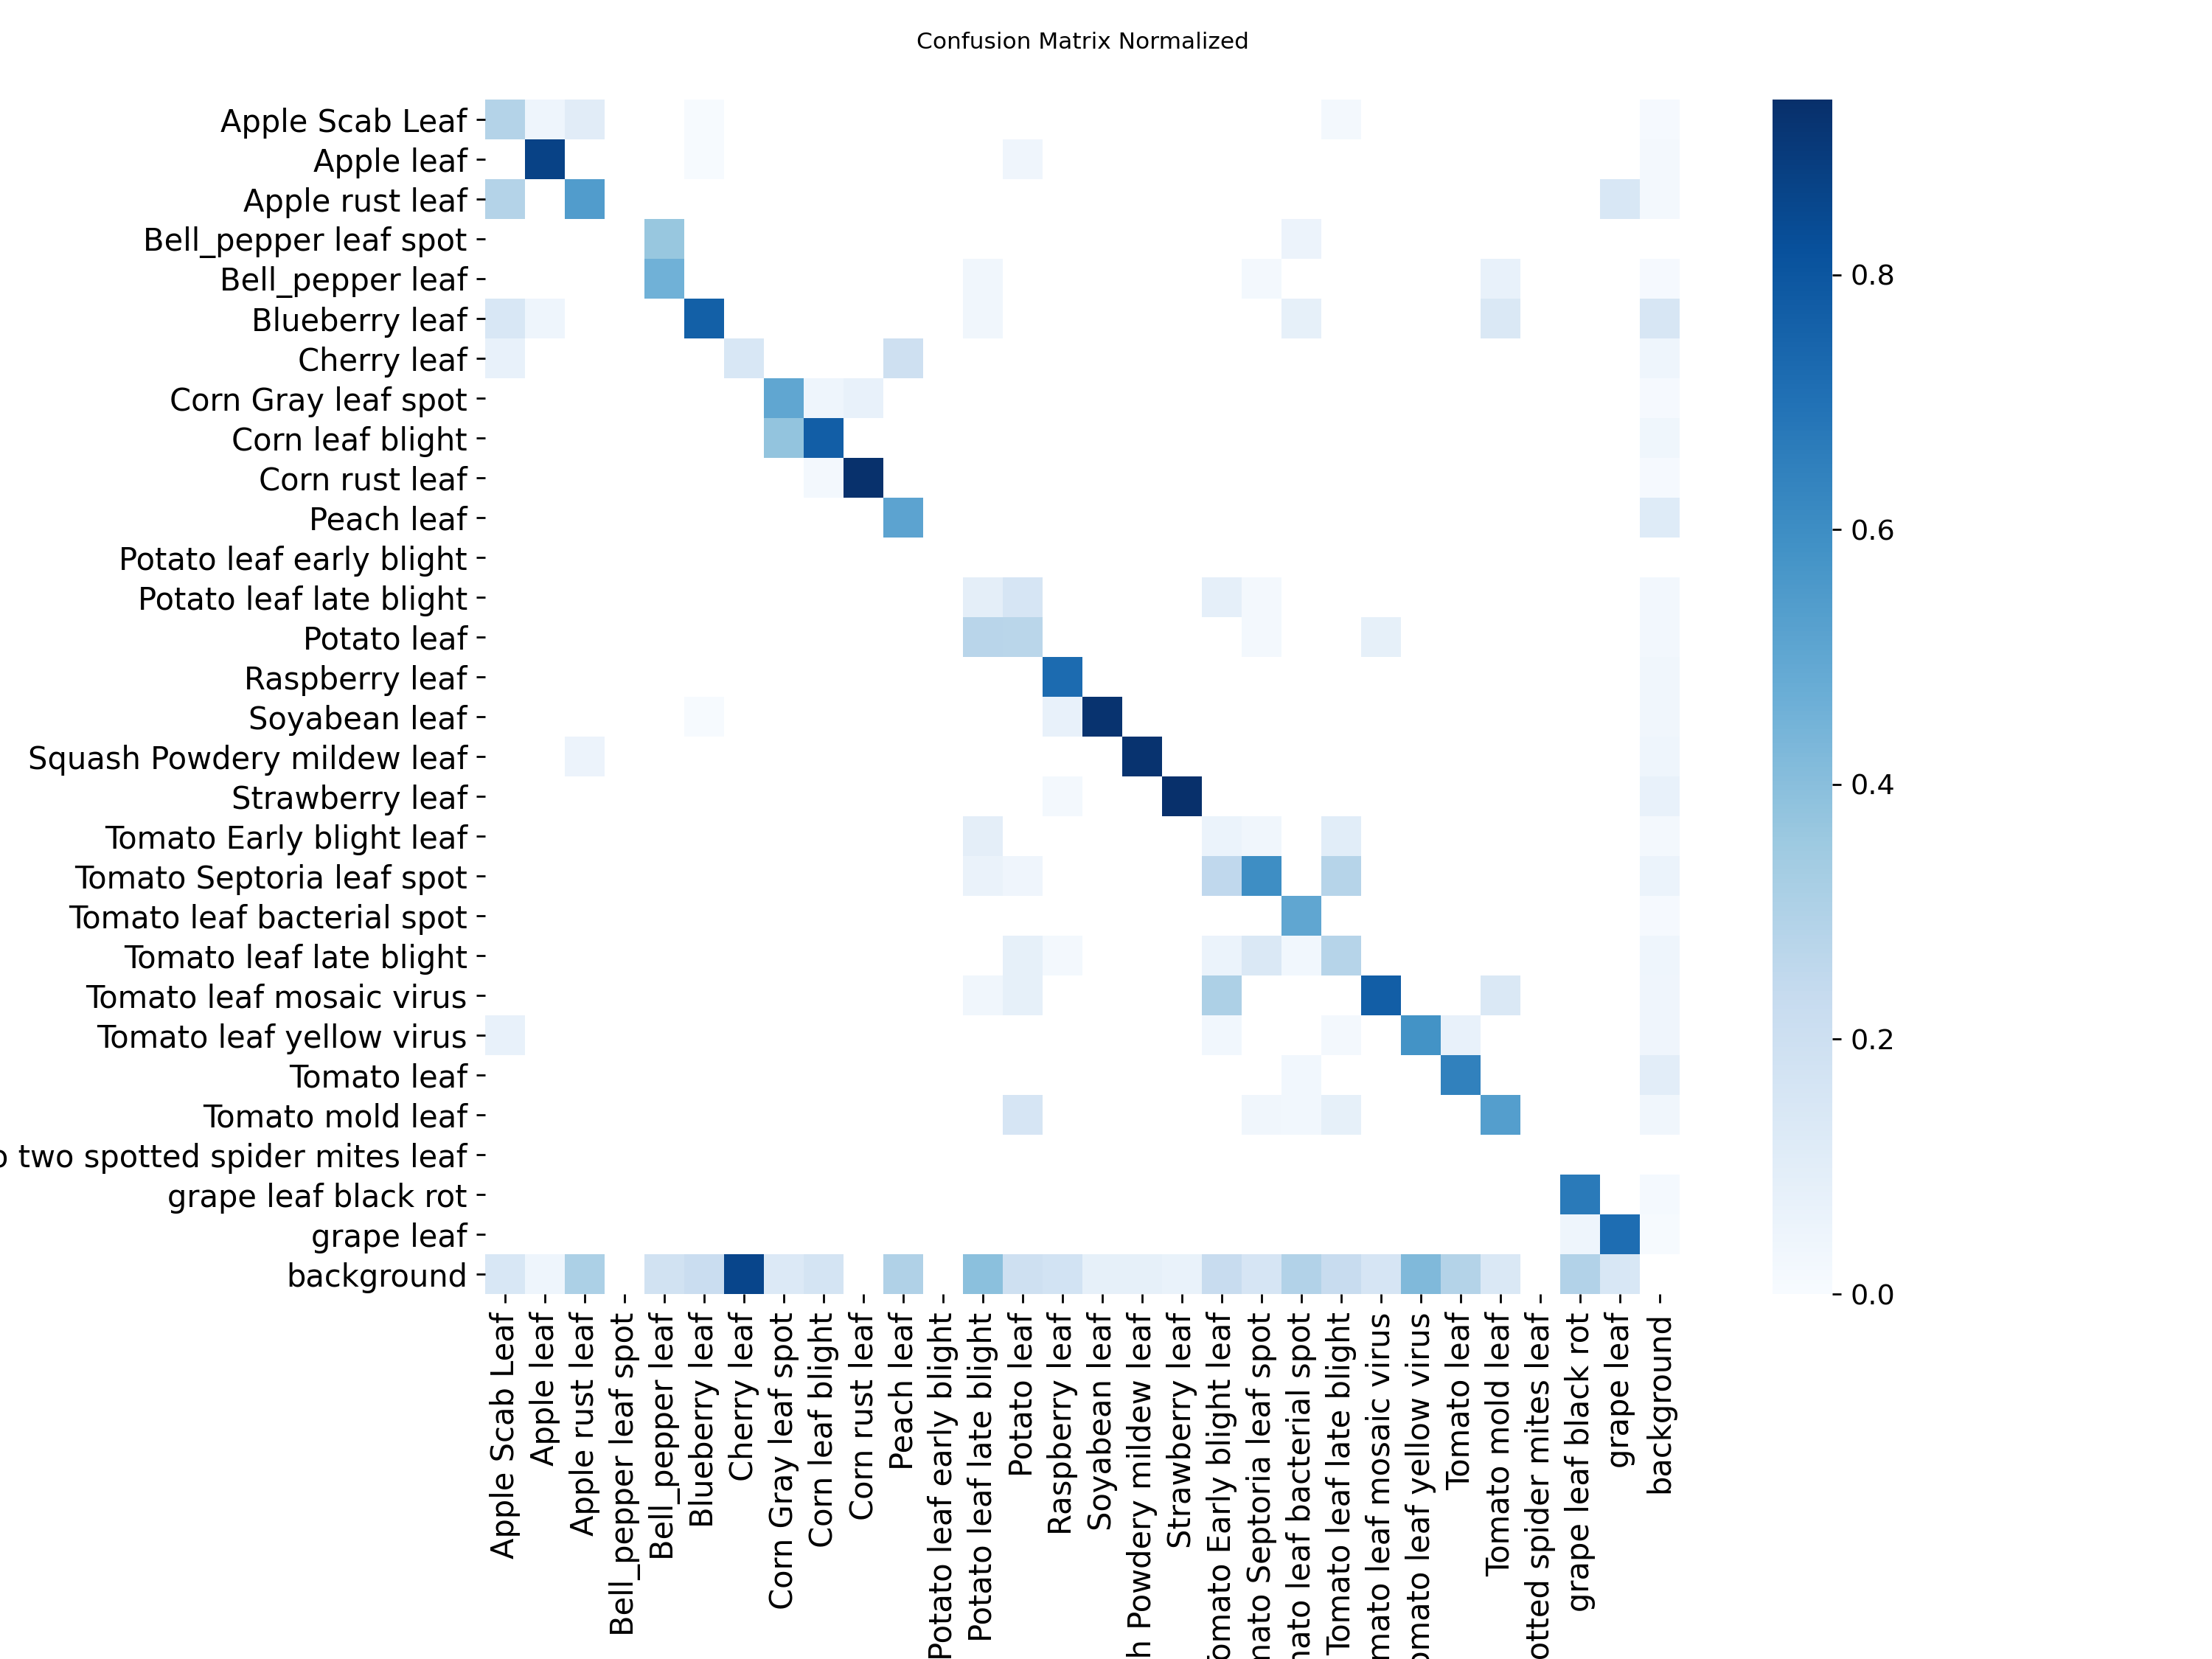

In [6]:
from IPython.display import Image, display
run = ROOT / "runs" / "crop_disease"
for f in ("results.png", "confusion_matrix_normalized.png"):
    if (run / f).exists():
        display(Image(filename=str(run / f)))

## Try it on a few test images

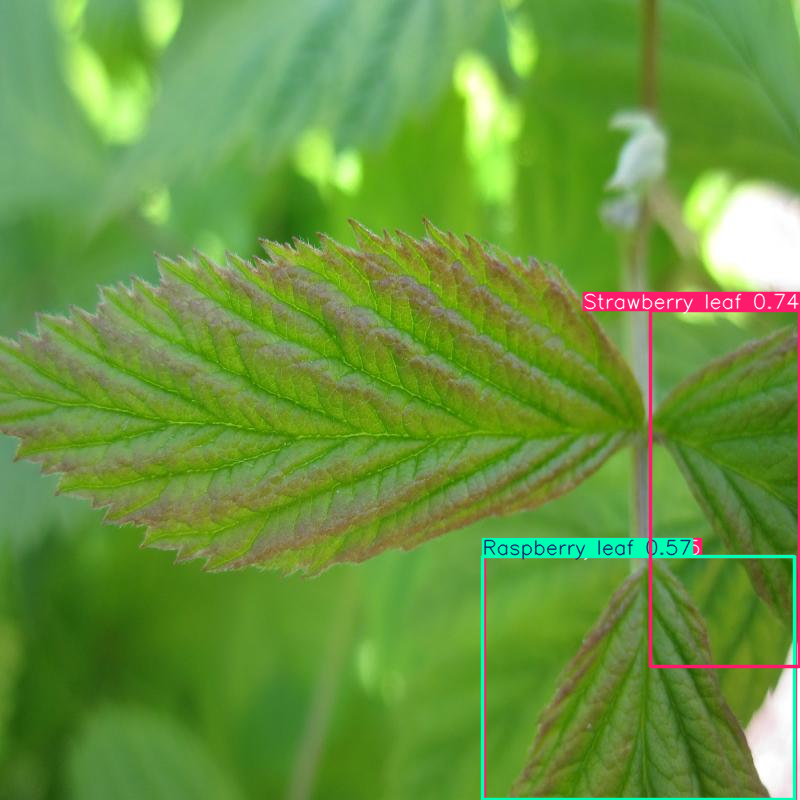

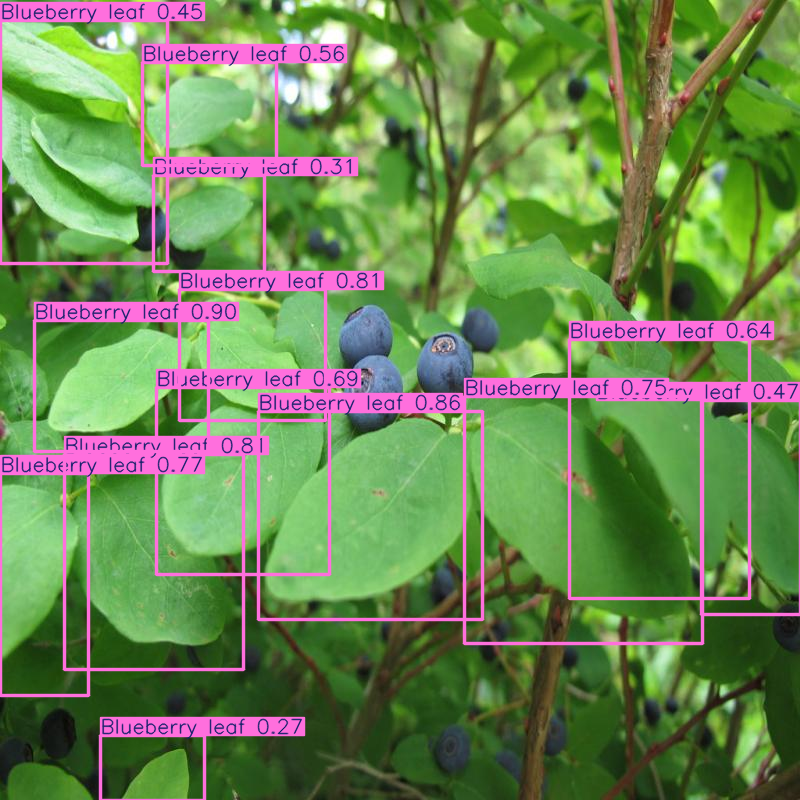

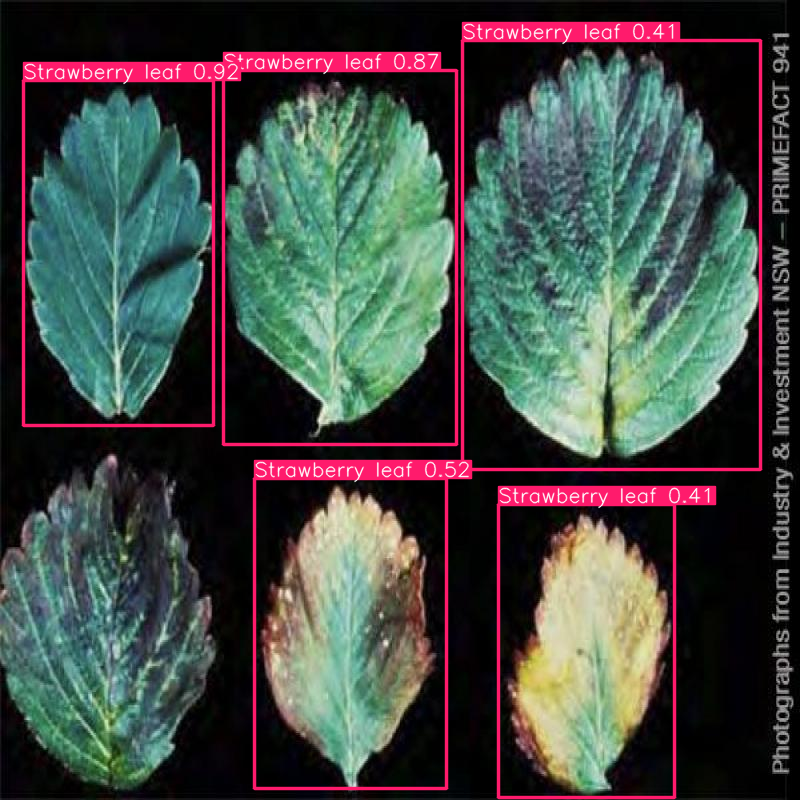

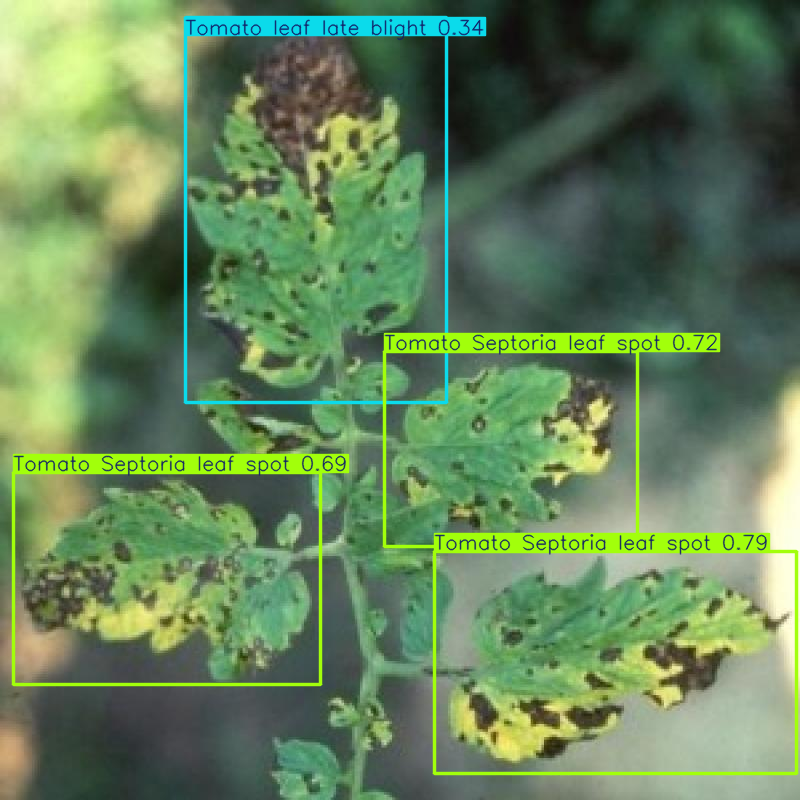

In [7]:
import random
from PIL import Image as PILImage
imgs = random.sample(list((DATASET / "test" / "images").glob("*")), 4)
for p in imgs:
    r = model.predict(str(p), conf=0.25, device=0, verbose=False)[0]
    display(PILImage.fromarray(r.plot()[..., ::-1]))

## Copy the model for the app
This puts `best.pt` where the web app expects it.

In [8]:
import shutil
APP_MODELS = ROOT.parent / "app" / "models"
APP_MODELS.mkdir(parents=True, exist_ok=True)
shutil.copy(BEST, APP_MODELS / "best.pt")
print("Copied to", APP_MODELS / "best.pt")

Copied to G:\crop disease\app\models\best.pt
